SEC7_Thermal System

37. Program - 1 - Plot and visualize the streamlines of the fluid flow
38. Program - 2 - Analyse the Diesel Cycle with python Program
39. Program - 3 - One Dimensional Heat Equation with Animated Plot
40. Program - 4 - Temperature Distribution - 2D Heat Transfer Problem
41. Program - 5 - Flow Over Cylinder - Stream Line Plot
42. Program - 6 - Flow Over Cylinder :- Pressure Distribution



In [ ]:
# 37. Program - 1 - Plot and visualize the streamlines of the fluid flow
print('################# \n')
import numpy as np
import matplotlib.pyplot as plt

n = 5
xp = np.linspace(-n, n, 50)
yp = np.linspace(-n, n, 50)

x, y = np.meshgrid(xp, yp) #mesh grip X,Y


plt.figure(figsize=(5,5))
plt.scatter(x,y)  #mesh
plt.show()


u= x**2+y-1  #U-component  of fluid velocity
#u=x**2+y**2
v=x+y**2+1   #Y-component of fluid velocity
#v=x**2+y**2


plt.figure(figsize=(5,5))
fluid_streams=plt.streamplot(x,y,u,v,color=np.sqrt(u**2+v**2),density=[1,1],cmap='jet')
plt.colorbar((fluid_streams).lines)
plt.title('fluid_streams')
plt.xlabel('U')
plt.ylabel('V')
plt.show()

print('################# \n')



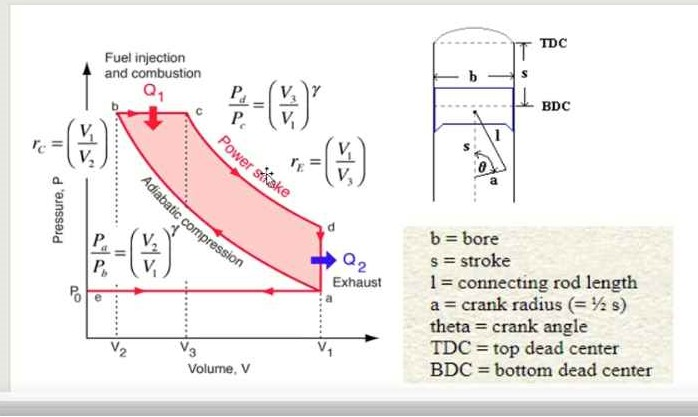

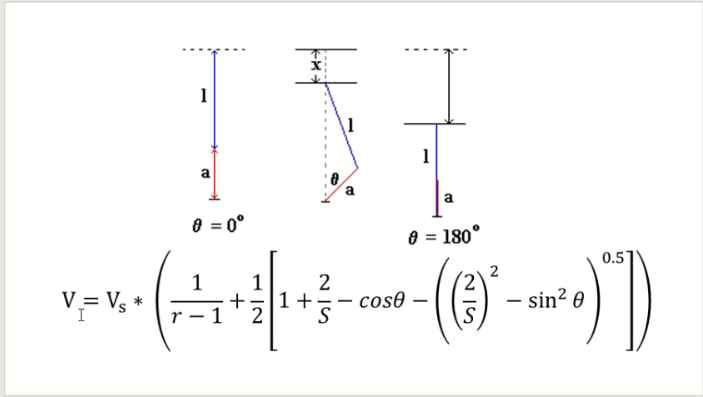

In [ ]:
38. Program - 2 - Analyse the Diesel Cycle with python Program

In [ ]:
#  Diesel Cycle Simulator given
import numpy as np
from numpy import pi, sin, cos, sqrt
import matplotlib.pyplot as plt

def volume(d,s,l,r,theta):
    Vs = (pi/4)*d**2*s
    Vc = Vs/(r-1)
    term1 = 1/(r-1)
    term2 = 1 + (2/s) - cos(theta)
    term3 = sqrt((2/s)**2 + (sin(theta))**2)
    V = Vs*(term1 + 0.5*(term2-term3))

    return V

d = 0.1   # bore
s = 0.1   # stroke
l = 0.15  # length of CR
r = 12    # Compression Ratio

p1 = 101.3
t1 = 300
gamma = 1.4
t3 = 2500

Vs = (np.pi/4)*d**2*s  # swept volume
Vc = Vs/(r-1)
v1 = Vs + Vc
v2 = Vc
v4 = v1
p2 = p1*(r)**gamma   # adiabatic process - p1v1**gamma = p2v2**gamma
t2 = t1 * r**(gamma-1)
p3 = p2

v3 = v2*t3/t2
p4 = p3*(v3/v4)**gamma

theta = 0

while theta < np.pi:
    theta = theta + 0.001
    v_theata = volume(d,s,l,r,theta)
    if(0 < (v_theata-v3) < 0.001):
          break

print(theta*180/pi)

V_comp = volume(d,s,l,r,np.linspace(0,pi,180))
P_comp = (p1*v1**gamma)/V_comp**gamma

V_exp = volume(d,s,l,r,np.linspace(pi,theta,180))
P_exp = (p3*v3**gamma)/V_exp**gamma

plt.figure(figsize=(10,10))
plt.plot(V_comp,P_comp)
plt.plot([v2,v3],[p2,p3])
plt.plot(V_exp,P_exp)
plt.plot([v4,v1],[p4,p1])

plt.title("PV Diagram Diesel Cycle",fontsize = 15)
plt.xlabel("Volume",fontsize = 15)
plt.ylabel("Pressure",fontsize = 15)
plt.ticklabel_format(style='sci', axis='x',scilimits=(0,0))
plt.ticklabel_format(style='sci', axis='y',scilimits=(0,0))
plt.show()


# 38. Program - 2 - Analyse the Diesel Cycle with python Program.
# not working

print('################# \n')
import numpy as np
import matplotlib as plt
from numpy import sin,cos,sqrt,pi

# import matplotlib.pyplot as plt
# SI units   length  m

d = 0.1  # bore diameter M
s = 0.1  # stroke = 2* crank M
l = 0.15  # length of CR conRod
r = 12  # Compression Ratio

Pintake = 101.3  # at pressure  a inlet P1
Tintake = 300  # at temperature  a inlet T1
gamma = 1.4  # constant
Tcombustion = 2500  # max temperature of cycle at c exhaust T3 kelavin

theta =0

def volume(d,s,l,r,theta): #volume  function
    Vs=(pi/4)*s*d**2  # swept volume # V0 t0 V1 in fig or total volume
    Vc=Vs/(r-1)     # clearance volume VC=V1->V2

    Term1=1/r-1
    Term2=1+(2/s)-cos(theta)
    Term3=sqrt(((2/s)**2)-(sin(theta))**2)

    V=Vs*(Term1+0.5*(Term2-Term3)) # total volume at Theta

    print("volume V=",V,"@theta=",theta)
    #print("volume V=",v,"theta=",theta,vs,vc)
    return (V)
    #return (v,vs,vc)

print('################# \n')
# compression volume
#@ A V1,T1,P1 -> #@ B V2,T2,P2 -> #@ C V3,T3,P3 -> #@ D V4,T4,P4
#@ A V1,T1,P1 ->commpression -> #@ B V2,T2,P2
#@ B V2,T2,P2 -> Fuel injection -> #@ C V3,T3,P3_>Q1
#@ C V3,T3,P3 -> power stroke  -> #@ D V4,T4,P4
#@ D V4,T4,P4 ->Exhaust ->#@ A V1,T1,P1 _>Q2


VswaptVolume  =(pi/4)*s*d**2# V0 t0 V1 in fig or total volume Vs
VclearanceVolume=VswaptVolume/(r-1)  # clearance volume VC=V1->V2
Vintake =VswaptVolume+VclearanceVolume  # pointA V1+V2
Ttop=Tintake*r**(gamma-1)#T2=T1*r**(gamma-1)
Vexhust = Vintake # pointD V4=V1

#for compression  adiabatic process - p1v1**gamma = p2v2**gamma
Vtop  = VclearanceVolume   #V2
#Constant  pressure   V prop to Temperature
Vcombustion = Vtop*(Tcombustion/Ttop) #V3=V2*(T3/T2)

Ptop=Pintake*(Vintake/Vtop)**gamma # adiabatic process P2/P1=(V1/V2)**gamma
Pcombustion=Ptop # P3=P2
Pexhust=(Vcombustion/Vexhust)**gamma # P4 =P3(V3/V4)**gamma

while theta<pi:
    theta=theta+0.001
    V_theta=volume(d,s,l,r,theta) # V_theta =volume at  theta
    if(0<(V_theta-Vcombustion)<0.001):
        #if ((0<(abs(V_theta-V3)))<0.001) angle is equal to V3
        break

#print(theta*180/pi)

V_compG=volume(d,s,l,r,numpy.linspace(0,pi,180))
#V_compG=volume(d,s,l,r,theta)
P_compG=Ptop*(Vintake/V_compG)**gamma


V_expG = volume(d,s,l,r,numpy.linspace(pi,theta,180))
#P_expG = (p3*v3**gamma)/V_exp**gamma
P_expG = (Pcombustion*Vcombustion**gamma)/V_expG**gamma


print(V_compG,P_compG)
print(V_expG,P_expG)



plt.figure(figsize=(10,10))
plt.plot(V_compG,P_compG)
#plt.plot([v2,v3],[p2,p3])
print(V_expG,P_expG)
#plt.plot([v4,v1],[p4,p1])

plt.title("PV Diagram Diesel Cycle",fontsize = 15)
plt.xlabel("Volume",fontsize = 15)
plt.ylabel("Pressure",fontsize = 15)
plt.ticklabel_format(style='sci', axis='x',scilimits=(0,0))
plt.ticklabel_format(style='sci', axis='y',scilimits=(0,0))
plt.show()

